# Centros F  — Grupo 4

In [84]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from pathlib import Path
from types import SimpleNamespace
from scipy.optimize import curve_fit, brentq, minimize_scalar
from scipy.special import spherical_jn, spherical_kn
from scipy.sparse.linalg import LinearOperator, eigsh
from scipy.linalg import eigh_tridiagonal

In [85]:
# Constantes (eV, Å, nm)
hc = 1239.84193        # eV·nm        -> E = hc/λ
hb2_2m = 3.80998       # ħ²/(2 m_e)   en eV·Å²
e2_4pieps0 = 14.3996   # e²/(4π ε0)   en eV·Å
M_madelung = 1.7476    # constante de Madelung (estructura tipo NaCl)

# Tabla de la clase: constante de red a (Å) y energía de transición del centro F (eV)
a_red  = pd.Series({"LiF": 4.028, "NaF": 4.634, "NaCl": 5.640, "KCl": 6.294, "KBr": 6.596})
E_tabla = pd.Series({"LiF": 5.083, "NaF": 3.702, "NaCl": 2.746, "KCl": 2.295, "KBr": 2.059})

# ε∞ = n² (constante dieléctrica de alta frecuencia) — valores de tablas, VERIFICAR antes de citar
eps_inf = pd.Series({"LiF": 1.92, "NaF": 1.74, "NaCl": 2.25, "KCl": 2.17, "KBr": 2.33})

# Piso de incerteza relativa (1 %) por variabilidad muestra a muestra: evita que un solo haluro domine los ajustes
SIGMA_PISO = 0.01

# 1. Datos

In [86]:
DATA_DIR = next(Path("data").glob("Scan - Lambda 35*"))

def leer_asc(nombre):
    # Los .asc de UV WinLab tienen 86 líneas de encabezado y usan coma decimal
    df = pd.read_csv(DATA_DIR / f"{nombre}.Sample.Raw.asc", sep=r"\s+", skiprows=86,
                     header=None, decimal=",", engine="python")
    df.columns = ["lambda", "A"]
    return df.sort_values("lambda").reset_index(drop=True)

# G4 = nuestros datos; G2_FLi es el LiF de otro grupo (sólo para comparar)
archivos = ["G4_NaCl", "G4_ClK", "G4_KBr", "G4_FNa", "G4_FLi", "G4_FLi_2", "G4_FLi_amarillo", "G2_FLi"]
espectros = {nombre: leer_asc(nombre) for nombre in archivos}
nada = leer_asc("nada vs nada")      # línea base del equipo (|A| < 3e-4: no se resta)

## Espectros

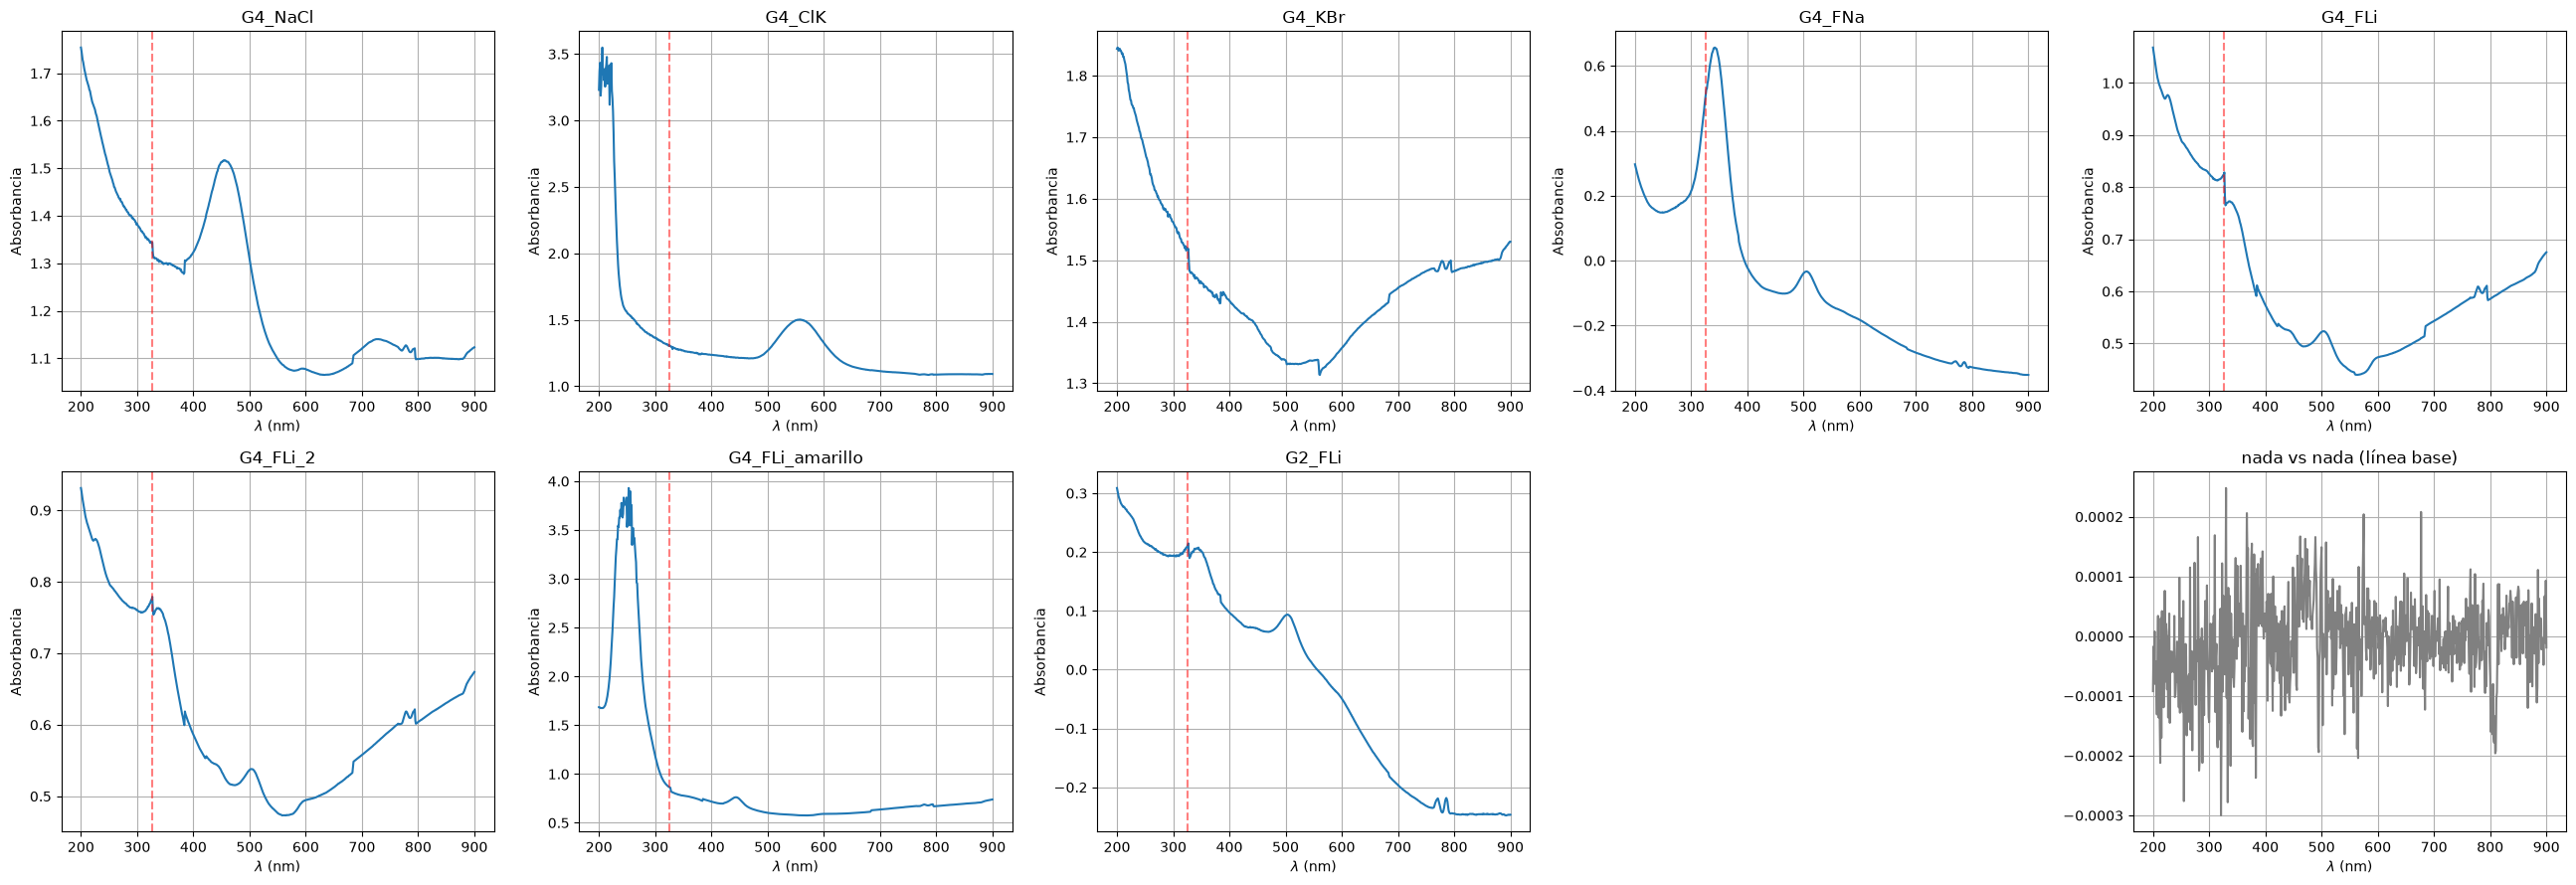

In [87]:
fig, axs = plt.subplots(2, 5, figsize=(26, 9))

for ax, (nombre, df) in zip(axs.flat, espectros.items()):
    ax.plot(df["lambda"], df["A"])
    ax.axvline(326, color="red", linestyle="--", alpha=0.5)    # cambio de lámpara (deuterio -> halógena)
    ax.set_title(nombre)
    ax.set_xlabel(r"$\lambda$ (nm)"); ax.set_ylabel("Absorbancia")
    ax.grid(True)

axs.flat[len(espectros)].axis("off")
axs.flat[-1].plot(nada["lambda"], nada["A"], color="gray")
axs.flat[-1].set_title("nada vs nada (línea base)")
axs.flat[-1].set_xlabel(r"$\lambda$ (nm)")
axs.flat[-1].grid(True)
plt.tight_layout()
plt.show()

## LiF? Banda de 506 nm vs banda M del NaF

In [88]:
# Ajuste de UNA gaussiana + recta en una ventana chica, para ubicar una banda puntual
def gauss_lineal(x, A, c, sigma, fondo, pendiente):
    return A * np.exp(-((x - c) ** 2) / (2 * sigma**2)) + fondo + pendiente * (x - 500)

casos = {
    # espectro: (ventana en nm, valores iniciales [A, centro, sigma, fondo, pendiente])
    "G2_FLi":          ((430, 580), [0.03, 505, 20, 0.05, -0.001]),
    "G4_FLi":          ((430, 580), [0.03, 505, 15, 0.5, 0.0]),
    "G4_FLi_2":        ((430, 580), [0.03, 505, 15, 0.5, 0.0]),
    "G4_FNa":          ((440, 600), [0.07, 507, 15, -0.1, -0.001]),   # banda M del NaF
    "G4_FLi_amarillo": ((400, 520), [0.15, 445, 20, 0.7, 0.0]),       # banda M del LiF
}
filas = {}
for nombre, ((lo, hi), p0) in casos.items():
    df = espectros[nombre]
    m = (df["lambda"] >= lo) & (df["lambda"] <= hi)
    popt, pcov = curve_fit(gauss_lineal, df.loc[m, "lambda"], df.loc[m, "A"], p0=p0, maxfev=20000)
    filas[nombre] = {"centro (nm)": popt[1], "err (nm)": np.sqrt(pcov[1, 1]), "sigma (nm)": abs(popt[2]), "altura": popt[0]}

# Las "FLi" (no amarillo) tienen la banda en ~506 nm, igual que la banda M del NaF -> se usa G4_FLi_amarillo como LiF
pd.DataFrame(filas).T.round(2)

,centro (nm),err (nm),sigma (nm),altura
G2_FLi,505.93,0.23,19.05,0.06
G4_FLi,505.71,0.36,12.13,0.05
G4_FLi_2,506.08,0.45,11.35,0.03
G4_FNa,506.96,0.16,15.83,0.09
G4_FLi_amarillo,444.76,0.09,10.97,0.09


# 2. Ajuste de la banda F: 2 gaussianas + fondo lineal

$$A(\lambda) = A_1 e^{-\frac{(\lambda-\lambda_1)^2}{2\sigma_1^2}} + A_2 e^{-\frac{(\lambda-\lambda_2)^2}{2\sigma_2^2}} + a + b(\lambda-500)$$

In [89]:
def doble_gaussiana(x, amplitud_1, centro_1, sigma_1, amplitud_2, centro_2, sigma_2, fondo, pendiente):
    # Gaussiana 1 = banda F (su centro es λ_max). Gaussiana 2 = banda M u hombro. Recta = scattering/reflexión del cristal
    gaussiana_1 = amplitud_1 * np.exp(-((x - centro_1) ** 2) / (2 * sigma_1**2))
    gaussiana_2 = amplitud_2 * np.exp(-((x - centro_2) ** 2) / (2 * sigma_2**2))
    return gaussiana_1 + gaussiana_2 + fondo + pendiente * (x - 500)

# haluro: (archivo, ventana de ajuste en nm, p0 = [A1, λ1, σ1, A2, λ2, σ2, fondo, pendiente], A máxima confiable)
config_ajuste = {
    "LiF":  ("G4_FLi_amarillo", (205, 600), [3.5, 250, 20, 0.1, 445, 20, 0.7, 0.0], 3.0),   # el pico satura: se descartan A > 3
    "NaF":  ("G4_FNa",          (250, 700), [0.6, 342, 25, 0.1, 505, 20, 0.0, -0.001], None),
    "NaCl": ("G4_NaCl",         (400, 880), [0.4, 456, 30, 0.05, 725, 40, 1.1, 0.0], None),
    "KCl":  ("G4_ClK",          (420, 880), [0.3, 557, 35, 0.02, 800, 40, 1.1, 0.0], None),
    "KBr":  ("G4_KBr",          (565, 880), [0.1, 650, 60, 0.01, 780, 20, 1.4, 0.0], None),  # sin banda F clara
}

# Ventanas alternativas: cuánto se mueve el centro al cambiar la ventana -> incerteza sistemática
ventanas_alt = {
    "LiF":  [(210, 520), (205, 340)],
    "NaF":  [(260, 600), (240, 800)],
    "NaCl": [(420, 800), (380, 900)],
    "KCl":  [(450, 800), (400, 900)],
    "KBr":  [(580, 880), (540, 880)],
}

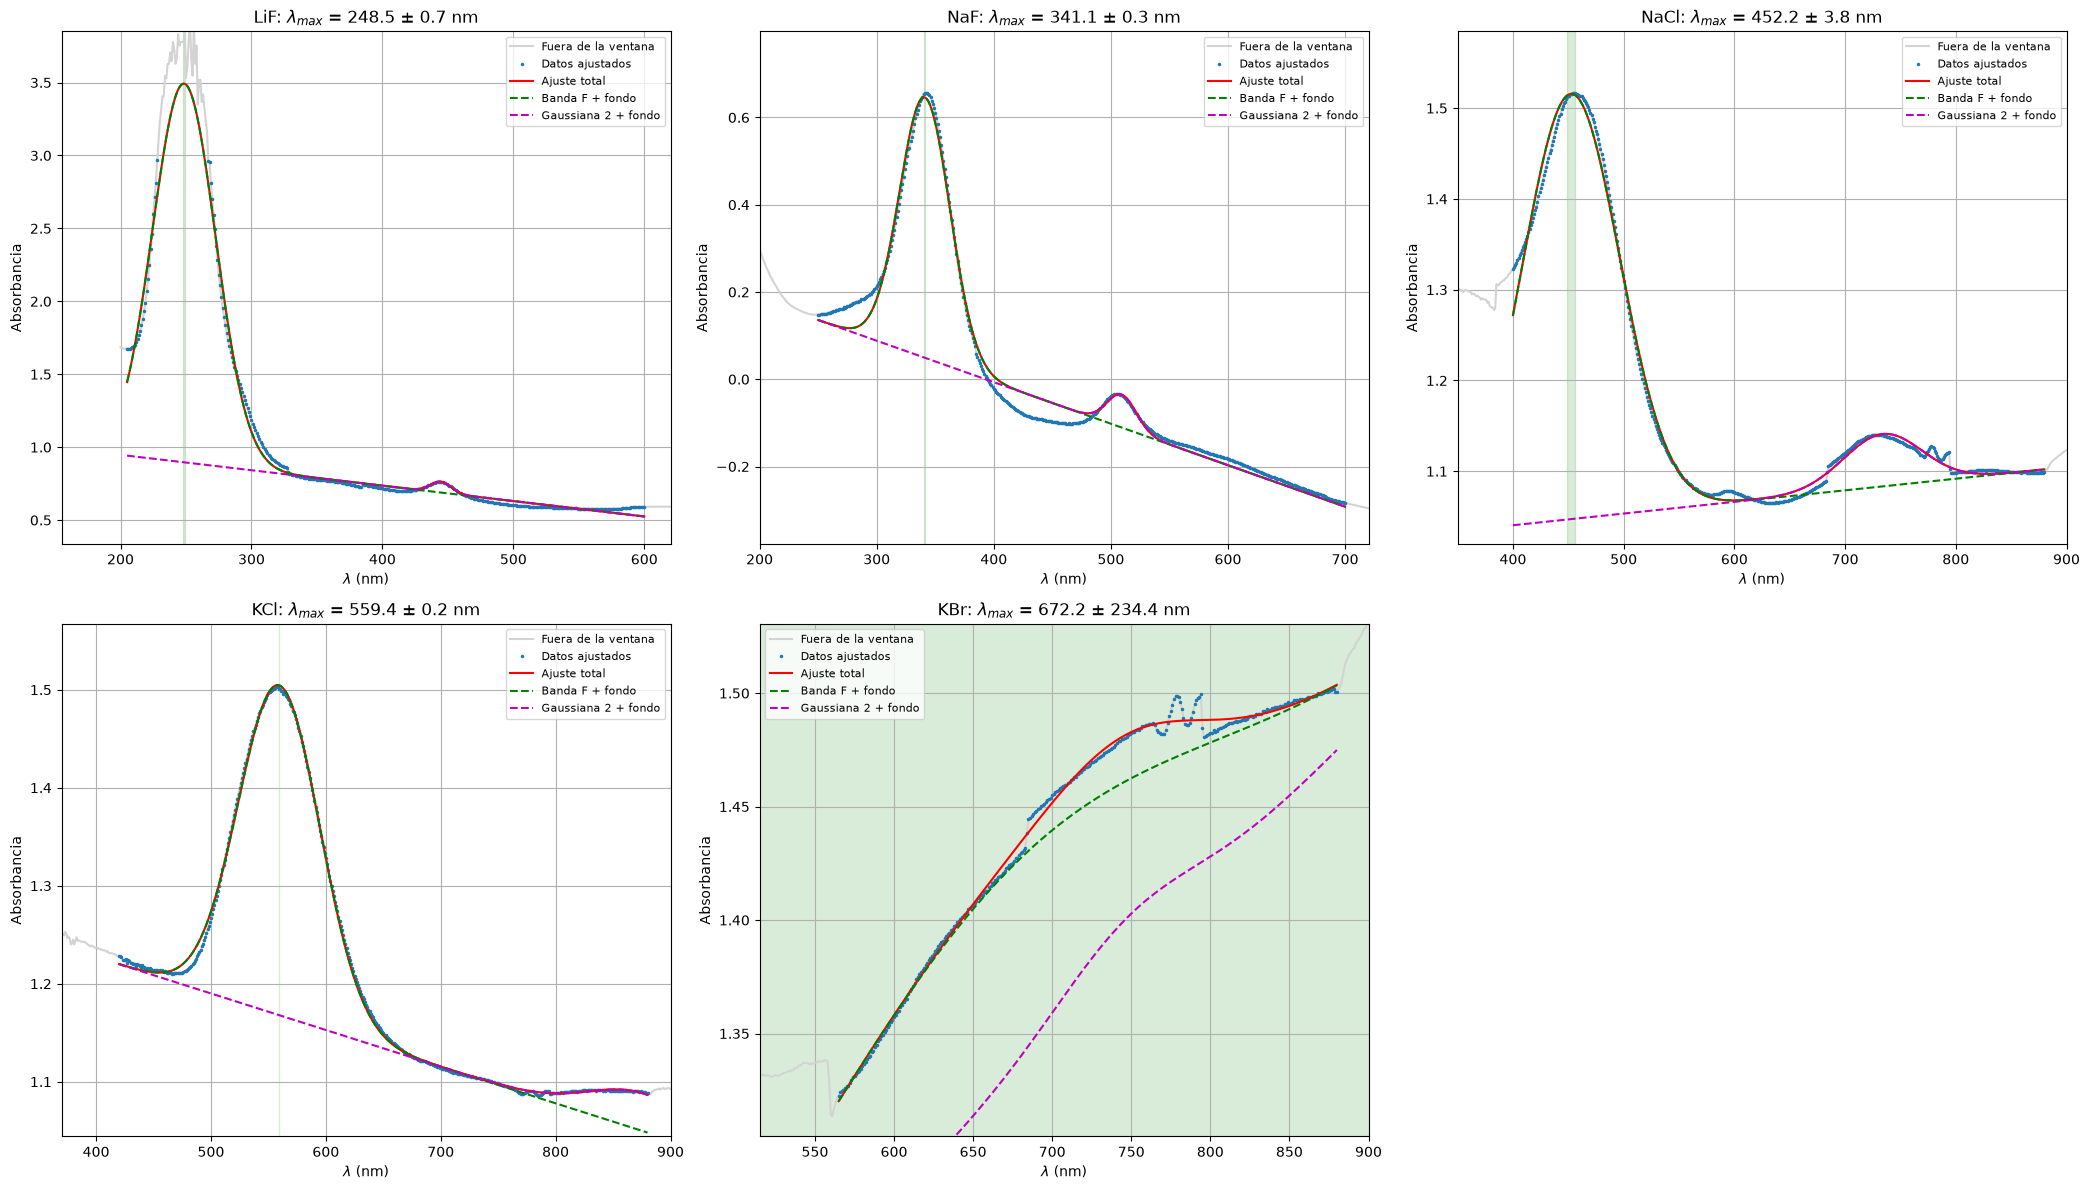

In [90]:
def ajustar_F(archivo, ventana, p0, A_sat):
    df = espectros[archivo]
    l_min, l_max = ventana
    mascara = (df["lambda"] >= l_min) & (df["lambda"] <= l_max)
    if A_sat is not None:
        mascara &= df["A"] < A_sat                      # saco los puntos saturados
    x = df.loc[mascara, "lambda"].to_numpy()
    y = df.loc[mascara, "A"].to_numpy()
    # Cotas: amplitudes >= 0, centros cerca de la ventana, anchos entre 2 y 300 nm; fondo y pendiente libres
    limites_inf = [0, l_min - 200, 2, 0, l_min - 200, 2, -np.inf, -np.inf]
    limites_sup = [np.inf, max(l_max + 100, 700), 300, np.inf, max(l_max + 100, 700), 300, np.inf, np.inf]
    popt, pcov = curve_fit(doble_gaussiana, x, y, p0=p0, bounds=(limites_inf, limites_sup), maxfev=50000)
    perr = np.sqrt(np.diag(pcov))
    R2 = 1 - np.sum((y - doble_gaussiana(x, *popt)) ** 2) / np.sum((y - y.mean()) ** 2)
    return popt, perr, R2, x, y

resultados, ajustes = {}, {}
for haluro, (archivo, ventana, p0, A_sat) in config_ajuste.items():
    popt, perr, R2, x, y = ajustar_F(archivo, ventana, p0, A_sat)

    # Repito el ajuste con las ventanas alternativas y tomo la mitad del rango de centros como error sistemático
    centros = [popt[1]] + [ajustar_F(archivo, v, p0, A_sat)[0][1] for v in ventanas_alt[haluro]]
    sist = (max(centros) - min(centros)) / 2

    resultados[haluro] = {
        "archivo": archivo,
        "lambda_F (nm)": popt[1],
        "err ajuste (nm)": perr[1],
        "sist. ventana (nm)": sist,
        "err lambda_F (nm)": np.hypot(perr[1], sist),   # estadístico ⊕ sistemático
        "sigma_F (nm)": popt[2],
        "R2": R2,
    }
    ajustes[haluro] = (archivo, ventana, popt, x, y, resultados[haluro]["err lambda_F (nm)"])

fig, axs = plt.subplots(2, 3, figsize=(21, 12))
for ax, (haluro, (archivo, (l_min, l_max), popt, x, y, err_tot)) in zip(axs.flat, ajustes.items()):
    df = espectros[archivo]
    x_fino = np.linspace(l_min, l_max, 2000)
    fondo = popt[6] + popt[7] * (x_fino - 500)
    ax.plot(df["lambda"], df["A"], color="lightgray", label="Fuera de la ventana")
    ax.plot(x, y, ".", markersize=3, label="Datos ajustados")
    ax.plot(x_fino, doble_gaussiana(x_fino, *popt), "r-", label="Ajuste total")
    ax.plot(x_fino, fondo + popt[0] * np.exp(-((x_fino - popt[1]) ** 2) / (2 * popt[2] ** 2)), "g--", label="Banda F + fondo")
    ax.plot(x_fino, fondo + popt[3] * np.exp(-((x_fino - popt[4]) ** 2) / (2 * popt[5] ** 2)), "m--", label="Gaussiana 2 + fondo")
    ax.axvspan(popt[1] - err_tot, popt[1] + err_tot, color="green", alpha=0.15)
    ax.set_xlim(l_min - 50, l_max + 20)
    y_tope = max(y.max(), doble_gaussiana(x_fino, *popt).max())
    ax.set_ylim(y.min() - 0.1 * np.ptp(y), y_tope + 0.15 * np.ptp(y))
    ax.set_xlabel(r"$\lambda$ (nm)"); ax.set_ylabel("Absorbancia")
    ax.set_title(rf"{haluro}: $\lambda_{{max}}$ = {popt[1]:.1f} ± {err_tot:.1f} nm")
    ax.legend(fontsize=8); ax.grid(True)
axs.flat[-1].axis("off")
plt.tight_layout()
plt.show()

## Resultados: $\lambda_{max}$ y $E_F = hc/\lambda_{max}$

In [91]:
tabla = pd.DataFrame.from_dict(resultados, orient="index")
tabla["E_F (eV)"] = hc / tabla["lambda_F (nm)"]
tabla["err E_F (eV)"] = hc / tabla["lambda_F (nm)"] ** 2 * tabla["err lambda_F (nm)"]     # propagación: |dE/dλ| σ_λ
tabla["E tabla (eV)"] = E_tabla
tabla["dif. rel. E (%)"] = 100 * (tabla["E_F (eV)"] / tabla["E tabla (eV)"] - 1)
tabla["a (Å)"] = a_red
tabla["R0 = a/2 (Å)"] = a_red / 2            # distancia a primeros vecinos = radio de la vacante

tabla[["archivo", "lambda_F (nm)", "err ajuste (nm)", "sist. ventana (nm)", "err lambda_F (nm)",
       "E_F (eV)", "err E_F (eV)", "E tabla (eV)", "dif. rel. E (%)", "R2"]].round(3)

,archivo,lambda_F (nm),err ajuste (nm),sist. ventana (nm),err lambda_F (nm),E_F (eV),err E_F (eV),E tabla (eV),dif. rel. E (%),R2
LiF,G4_FLi_amarillo,248.531,0.122,0.668,0.679,4.989,0.014,5.083,-1.855,0.990
NaF,G4_FNa,341.066,0.205,0.192,0.281,3.635,0.003,3.702,-1.805,0.990
NaCl,G4_NaCl,452.212,0.169,3.754,3.758,2.742,0.023,2.746,-0.156,0.996
KCl,G4_ClK,559.367,0.075,0.197,0.211,2.217,0.001,2.295,-3.420,0.999
KBr,G4_KBr,672.207,28.523,232.699,234.441,1.844,0.643,2.059,-10.421,0.997


# 3. Ley de Mollwo-Ivey: $\lambda_{max} = C\,a^{n}$

todos: n = 1.764 ± 0.091,  C = 21.88 nm/Å^n,  R² = 0.9861
sin KBr: n = 1.763 ± 0.112,  C = 21.89 nm/Å^n,  R² = 0.9919


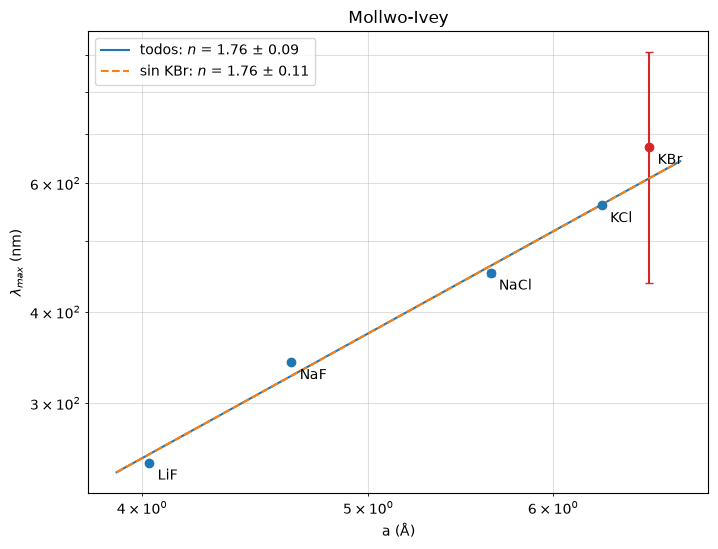

In [92]:
def recta_ponderada(x, y, sigma_y):
    # Recta y = m x + c con pesos 1/σ². absolute_sigma=False -> la incerteza se reescala con el χ² reducido
    popt, pcov = curve_fit(lambda x, m, c: m * x + c, x, y, sigma=sigma_y, absolute_sigma=False)
    return SimpleNamespace(slope=popt[0], intercept=popt[1], stderr=np.sqrt(pcov[0, 0]), rvalue=np.corrcoef(x, y)[0, 1])

def mollwo_ivey(haluros):
    # ln λ = ln C + n ln a. El error de ln λ es σ_λ/λ (con el piso de 1 %)
    t = tabla.loc[haluros]
    lna = np.log(t["a (Å)"].to_numpy(float))
    lnl = np.log(t["lambda_F (nm)"].to_numpy(float))
    sigma = np.hypot(t["err lambda_F (nm)"].to_numpy(float) / t["lambda_F (nm)"].to_numpy(float), SIGMA_PISO)
    return recta_ponderada(lna, lnl, sigma)

ajustes_MI = {
    "todos": mollwo_ivey(list(tabla.index)),
    "sin KBr": mollwo_ivey([h for h in tabla.index if h != "KBr"]),
}
for nombre, r in ajustes_MI.items():
    print(f"{nombre}: n = {r.slope:.3f} ± {r.stderr:.3f},  C = {np.exp(r.intercept):.2f} nm/Å^n,  R² = {r.rvalue**2:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
a_fino = np.linspace(3.9, 6.8, 200)
for h in tabla.index:
    ax.errorbar(tabla.loc[h, "a (Å)"], tabla.loc[h, "lambda_F (nm)"], yerr=tabla.loc[h, "err lambda_F (nm)"],
                fmt="o", color="tab:red" if h == "KBr" else "tab:blue", capsize=3)
    ax.annotate(h, (tabla.loc[h, "a (Å)"], tabla.loc[h, "lambda_F (nm)"]), textcoords="offset points", xytext=(6, -12))
for (nombre, r), estilo in zip(ajustes_MI.items(), ["-", "--"]):
    ax.plot(a_fino, np.exp(r.intercept) * a_fino**r.slope, estilo, label=rf"{nombre}: $n$ = {r.slope:.2f} ± {r.stderr:.2f}")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("a (Å)"); ax.set_ylabel(r"$\lambda_{max}$ (nm)")
ax.set_title("Mollwo-Ivey")
ax.legend(); ax.grid(True, which="both", alpha=0.4)
plt.show()

# 4. Pozos infinitos

- Cúbico de arista $a$: $\Delta E = \dfrac{3h^2}{8ma^2}$
- Esférico de radio $r_0=a/2$: $\Delta E = (4.493^2-\pi^2)\,\dfrac{\hbar^2}{2mr_0^2} = 10.315\,\dfrac{\hbar^2}{2mr_0^2}$

      a (Å)  E_F (eV)  E cúbico inf (eV)  E esférico inf (eV)  E_F / cúbico  E_F / esférico
LiF   4.028     4.989              6.953                9.689         0.717           0.515
NaF   4.634     3.635              5.253                7.320         0.692           0.497
NaCl  5.640     2.742              3.546                4.942         0.773           0.555
KCl   6.294     2.217              2.848                3.968         0.778           0.559
KBr   6.596     1.844              2.593                3.613         0.711           0.510


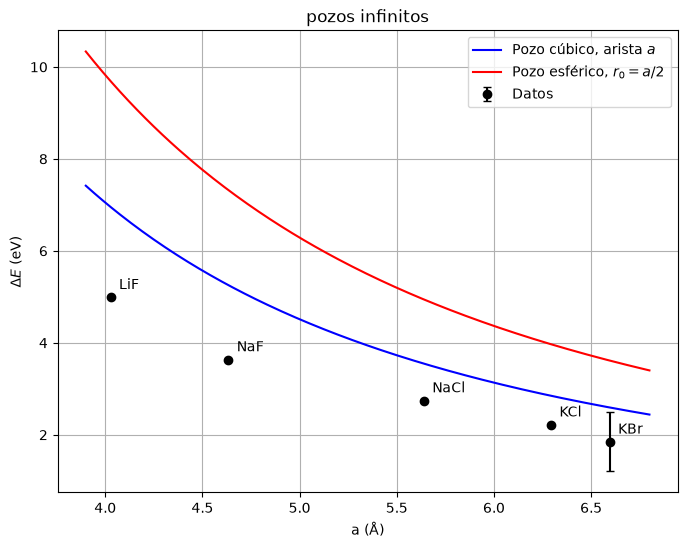

In [93]:
# Cúbico: niveles (ħ²π²/2ma²)(nx²+ny²+nz²); ΔE = (2,1,1) - (1,1,1) = 3 ħ²π²/(2ma²) = 3h²/(8ma²)
tabla["E cúbico inf (eV)"] = 3 * np.pi**2 * hb2_2m / tabla["a (Å)"] ** 2
# Esférico: E_nl = (ħ²/2m)(ξ_nl/r0)² con ξ_nl = ceros de j_l: ξ_1s = π, ξ_1p = 4.493
tabla["E esférico inf (eV)"] = 10.315 * hb2_2m / tabla["R0 = a/2 (Å)"] ** 2

comparacion = tabla[["a (Å)", "E_F (eV)", "E cúbico inf (eV)", "E esférico inf (eV)"]].astype(float)
comparacion["E_F / cúbico"] = comparacion["E_F (eV)"] / comparacion["E cúbico inf (eV)"]
comparacion["E_F / esférico"] = comparacion["E_F (eV)"] / comparacion["E esférico inf (eV)"]
print(comparacion.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(tabla["a (Å)"], tabla["E_F (eV)"].astype(float), yerr=tabla["err E_F (eV)"].astype(float), fmt="ko", capsize=3, label="Datos")
ax.plot(a_fino, 3 * np.pi**2 * hb2_2m / a_fino**2, "b-", label="Pozo cúbico, arista $a$")
ax.plot(a_fino, 10.315 * hb2_2m / (a_fino / 2) ** 2, "r-", label="Pozo esférico, $r_0=a/2$")
for h in tabla.index:
    ax.annotate(h, (tabla.loc[h, "a (Å)"], tabla.loc[h, "E_F (eV)"]), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("a (Å)"); ax.set_ylabel(r"$\Delta E$ (eV)")
ax.set_title("pozos infinitos")
ax.legend(); ax.grid(True)
plt.show()

# 5. Pozo esférico finito

$V(r) = -V_0$ para $r<r_0$, $0$ afuera. Condición de cuantización con $\xi=kr_0$, $\eta=\kappa r_0$:

$$\xi\, j_l'(\xi)\,k_l(\eta) - \eta\, k_l'(\eta)\, j_l(\xi) = 0,\qquad \xi^2+\eta^2 = z_0^2 = \frac{V_0\, r_0^2}{\hbar^2/2m}$$

In [94]:
# ------------------------------------------------------------------------------------------
# Estados ligados (-V0 < E < 0). La parte radial es:
#   adentro (r < r0):  R(r) = j_l(k r)     k = sqrt(2m(E+V0))/ħ   Bessel esférica (finita en r=0)
#   afuera  (r > r0):  R(r) = k_l(κ r)     κ = sqrt(-2mE)/ħ        Bessel modificada (decae a 0)
# En variables adimensionales ξ = k r0, η = κ r0 se cumple ξ² + η² = z0² (fijo por V0 y r0).
#
# Empalme en r0 (R y R' continuas) = igualar derivadas logarítmicas:
#       ξ j_l'(ξ) / j_l(ξ)  =  η k_l'(η) / k_l(η)
# Multiplico por j_l·k_l para sacar los denominadores (así la función no tiene polos y se
# pueden buscar raíces por cambio de signo):
#       F(ξ) = ξ j_l'(ξ) k_l(η) - η k_l'(η) j_l(ξ) = 0,     con η = sqrt(z0² - ξ²)
# ------------------------------------------------------------------------------------------

def condicion(xi, l, z0):
    eta = np.sqrt(np.clip(z0**2 - xi**2, 0, None))
    return (xi * spherical_jn(l, xi, derivative=True) * spherical_kn(l, eta)
            - eta * spherical_kn(l, eta, derivative=True) * spherical_jn(l, xi))

def xi_ligado(l, z0):
    # 1) recorro ξ en (0, z0) y busco el primer cambio de signo de F
    # 2) refino esa raíz con brentq (bisección + secante)
    # Primera raíz = estado ligado más bajo con ese l (1s para l=0, 1p para l=1). NaN si no hay.
    xs = np.linspace(1e-4, z0 - 1e-6, 2000)
    v = condicion(xs, l, z0)
    cambios = np.where(v[:-1] * v[1:] < 0)[0]
    if len(cambios) == 0:
        return np.nan
    i = cambios[0]
    return brentq(condicion, xs[i], xs[i + 1], args=(l, z0))

def niveles(V0, r0):
    # Devuelve E_1s, E_1p (medidas desde el borde del pozo, < 0) y E_1s medida desde el fondo
    z0 = r0 * np.sqrt(V0 / hb2_2m)
    xi_s, xi_p = xi_ligado(0, z0), xi_ligado(1, z0)
    E_s = hb2_2m * xi_s**2 / r0**2 - V0          # E = ħ²k²/2m - V0 = (ħ²/2m)(ξ/r0)² - V0
    E_p = hb2_2m * xi_p**2 / r0**2 - V0
    return E_s, E_p, hb2_2m * xi_s**2 / r0**2

def delta_E(V0, r0):
    E_s, E_p, _ = niveles(V0, r0)
    return E_p - E_s                             # energía de la transición 1s -> 1p

# Chequeo: para z0 -> ∞ las raíces tienden a los ceros de Bessel del pozo infinito (π y 4.493)
for z0 in [5, 10, 20, 30]:
    print(f"z0 = {z0:>2}:  xi(1s) = {xi_ligado(0, z0):.3f},  xi(1p) = {xi_ligado(1, z0):.3f}")
print(f"infinito:  xi(1s) = {np.pi:.3f},  xi(1p) = 4.493")

z0 =  5:  xi(1s) = 2.596,  xi(1p) = 3.679
z0 = 10:  xi(1s) = 2.852,  xi(1p) = 4.075
z0 = 20:  xi(1s) = 2.991,  xi(1p) = 4.278
z0 = 30:  xi(1s) = 3.040,  xi(1p) = 4.348
infinito:  xi(1s) = 3.142,  xi(1p) = 4.493


$V_0 =eV_{Mad}$
$$eV_{Mad} = \frac{e^2}{4\pi\varepsilon_0}\frac{M}{R_0},\qquad R_0=a/2$$

In [95]:
def ajustar_V0(E_medida, r0):
    # Busco V0 tal que ΔE(V0) = E_medida. ΔE sólo está definida si el 1p está ligado (z0 > π),
    # así que arranco la grilla en ese umbral, busco un cambio de signo y refino con brentq.
    V_umbral = hb2_2m * np.pi**2 / r0**2
    V_grilla = np.linspace(V_umbral * 1.001, 80, 300)
    dE = np.array([delta_E(V, r0) for V in V_grilla]) - E_medida
    cambios = np.where(dE[:-1] * dE[1:] < 0)[0]
    if len(cambios) == 0:
        return np.nan
    i = cambios[0]
    return brentq(lambda V: delta_E(V, r0) - E_medida, V_grilla[i], V_grilla[i + 1])

tabla["V0 ajustado (eV)"] = [ajustar_V0(tabla.loc[h, "E_F (eV)"], tabla.loc[h, "R0 = a/2 (Å)"]) for h in tabla.index]
tabla["eV_Mad (eV)"] = e2_4pieps0 * M_madelung / tabla["R0 = a/2 (Å)"]

# Modelo sin parámetros libres: V0 = eV_Mad, r0 = a/2
filas = {}
for h in tabla.index:
    r0, V_mad = tabla.loc[h, "R0 = a/2 (Å)"], tabla.loc[h, "eV_Mad (eV)"]
    E_s, E_p, E0_fondo = niveles(V_mad, r0)
    filas[h] = {
        "z0": r0 * np.sqrt(V_mad / hb2_2m),          # > π  <=>  el 1p está ligado
        "eV_Mad (eV)": V_mad,
        "E_1s (eV)": E_s,
        "E_1p (eV)": E_p,
        "ΔE Madelung (eV)": E_p - E_s,
        "E_F medida (eV)": tabla.loc[h, "E_F (eV)"],
        "dif. rel. (%)": 100 * ((E_p - E_s) / tabla.loc[h, "E_F (eV)"] - 1),
        "V0 ajustado (eV)": tabla.loc[h, "V0 ajustado (eV)"],
        "β = V0 ajustado / eV_Mad": tabla.loc[h, "V0 ajustado (eV)"] / V_mad,
        "E_i = eV_Mad - E0 (eV)": V_mad - E0_fondo,   # energía de ionización estimada
    }
madelung = pd.DataFrame.from_dict(filas, orient="index")
madelung.round(3)

,z0,eV_Mad (eV),E_1s (eV),E_1p (eV),ΔE Madelung (eV),E_F medida (eV),dif. rel. (%),V0 ajustado (eV),β = V0 ajustado / eV_Mad,E_i = eV_Mad - E0 (eV)
LiF,3.647,12.495,-7.007,-1.857,5.150,4.989,3.242,11.727,0.939,7.007
NaF,3.912,10.861,-6.562,-2.425,4.137,3.635,13.805,8.305,0.765,6.562
NaCl,4.316,8.924,-5.885,-2.889,2.996,2.742,9.286,7.009,0.785,5.885
KCl,4.559,7.996,-5.498,-3.010,2.488,2.217,12.251,5.720,0.715,5.498
KBr,4.667,7.630,-5.333,-3.037,2.296,1.844,24.473,4.304,0.564,5.333


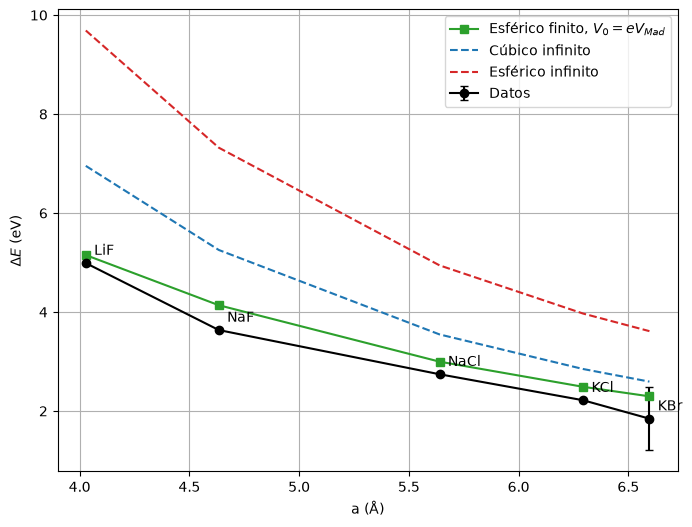

In [96]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(tabla["a (Å)"], tabla["E_F (eV)"], yerr=tabla["err E_F (eV)"], fmt="ko-", capsize=3, label="Datos")
ax.plot(tabla["a (Å)"], madelung["ΔE Madelung (eV)"], "s-", color="tab:green", label=r"Esférico finito, $V_0=eV_{Mad}$")
ax.plot(tabla["a (Å)"], tabla["E cúbico inf (eV)"], "--", color="tab:blue", label="Cúbico infinito")
ax.plot(tabla["a (Å)"], tabla["E esférico inf (eV)"], "--", color="tab:red", label="Esférico infinito")
for h in tabla.index:
    ax.annotate(h, (tabla.loc[h, "a (Å)"], tabla.loc[h, "E_F (eV)"]), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("a (Å)"); ax.set_ylabel(r"$\Delta E$ (eV)")
#ax.set_title("Banda F: medida vs modelos")
ax.legend(); ax.grid(True)
plt.show()

## $V_0=\beta\,eV_{Mad}$ con $\beta$ libre (un solo valor para todos los haluros)

β global = 0.820 ± 0.044   (β mínimo para que el 1p esté ligado: 0.742;  χ²_red = 25.7)
      eV_Mad (eV)  V0 = β·eV_Mad (eV)  V0 ajustado a cada E_F (eV)  β_i (cada haluro)  E_F medida (eV)  ΔE con eV_Mad (eV)  ΔE con β·eV_Mad (eV)  dif. Madelung (%)  dif. β global (%)
LiF        12.495              10.249                       11.727              0.939            4.989               5.150                 4.601              3.242             -7.762
NaF        10.861               8.909                        8.305              0.765            3.635               4.137                 3.780             13.805              3.984
NaCl        8.924               7.320                        7.009              0.785            2.742               2.996                 2.791              9.286              1.796
KCl         7.996               6.559                        5.720              0.715            2.217               2.488                 2.335             12.251              5.3

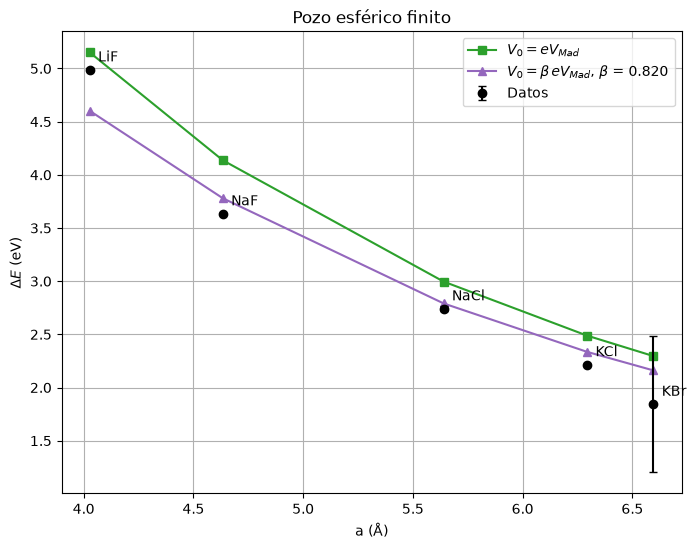

In [97]:
# V0 = β·eV_Mad con UN solo β libre (el mismo para todos los haluros) y r0 = a/2 fijo.
# Se ajusta por mínimos cuadrados ponderados a los 5 E_F medidos (pesos 1/σ², σ con piso de 1 %).
haluros = list(tabla.index)
E_med = tabla["E_F (eV)"].to_numpy(float)
sigma_E = np.hypot(tabla["err E_F (eV)"].to_numpy(float), SIGMA_PISO * E_med)
r0s = tabla["R0 = a/2 (Å)"].to_numpy(float)
V_mad = tabla["eV_Mad (eV)"].to_numpy(float)

def modelo_beta(idx, beta):
    # ΔE del pozo esférico finito para cada haluro con V0 = β·eV_Mad (mismo β para todos)
    return np.array([delta_E(beta * V_mad[int(i)], r0s[int(i)]) for i in idx])

# El 1p sólo está ligado si V0 > ħ²π²/(2m r0²): el β mínimo es el más exigente entre los haluros
beta_min = np.max(hb2_2m * np.pi**2 / r0s**2 / V_mad)
idx = np.arange(len(haluros))
popt, pcov = curve_fit(modelo_beta, idx, E_med, p0=[1.0], sigma=sigma_E, bounds=(1.001 * beta_min, 2.0))
beta_libre, err_beta = popt[0], np.sqrt(pcov[0, 0])
chi2_red = np.sum(((E_med - modelo_beta(idx, beta_libre)) / sigma_E) ** 2) / (len(haluros) - 1)
print(f"β global = {beta_libre:.3f} ± {err_beta:.3f}   (β mínimo para que el 1p esté ligado: {beta_min:.3f};  χ²_red = {chi2_red:.1f})")

dE_beta = modelo_beta(idx, beta_libre)
comparacion_beta = pd.DataFrame({
    "eV_Mad (eV)": V_mad,
    "V0 = β·eV_Mad (eV)": beta_libre * V_mad,
    "V0 ajustado a cada E_F (eV)": tabla["V0 ajustado (eV)"],
    "β_i (cada haluro)": tabla["V0 ajustado (eV)"] / V_mad,
    "E_F medida (eV)": E_med,
    "ΔE con eV_Mad (eV)": madelung["ΔE Madelung (eV)"],
    "ΔE con β·eV_Mad (eV)": dE_beta,
}, index=haluros)
comparacion_beta["dif. Madelung (%)"] = 100 * (comparacion_beta["ΔE con eV_Mad (eV)"] / E_med - 1)
comparacion_beta["dif. β global (%)"] = 100 * (comparacion_beta["ΔE con β·eV_Mad (eV)"] / E_med - 1)
print(comparacion_beta.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(tabla["a (Å)"], E_med, yerr=tabla["err E_F (eV)"], fmt="ko", capsize=3, label="Datos", zorder=5)
ax.plot(tabla["a (Å)"], comparacion_beta["ΔE con eV_Mad (eV)"], "s-", color="tab:green", label=r"$V_0=eV_{Mad}$")
ax.plot(tabla["a (Å)"], dE_beta, "^-", color="tab:purple", label=rf"$V_0=\beta\,eV_{{Mad}}$, $\beta$ = {beta_libre:.3f}")
for h in haluros:
    ax.annotate(h, (tabla.loc[h, "a (Å)"], tabla.loc[h, "E_F (eV)"]), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("a (Å)"); ax.set_ylabel(r"$\Delta E$ (eV)")
ax.set_title(r"Pozo esférico finito")
ax.legend(); ax.grid(True)
plt.show()

# 6. Pozo cúbico finito

$V=0$ para $|x|,|y|,|z|<a/2$ y $V=V_0$ afuera. 


aproximación separable $V\approx V_x+V_y+V_z$: tres pozos 1D finitos de ancho $a$, $E=e_{n_x}+e_{n_y}+e_{n_z}$.

In [98]:
# ------------------------------------------------------------------------------------------
# Pozo 1D finito de ancho a (semiancho b = a/2), con z = k·b y z0 = b·sqrt(V0/(ħ²/2m)).
# Empalmando la función y su derivada en x = ±b se obtiene:
#   estado par   (n=1):  z tan z  = sqrt(z0² - z²)  ->  z sin z - sqrt(z0²-z²) cos z = 0,  z ∈ (0, π/2)
#   estado impar (n=2): -z cot z  = sqrt(z0² - z²)  -> -z cos z - sqrt(z0²-z²) sin z = 0,  z ∈ (π/2, π)
# (raíces con brentq). Energía de cada nivel: e = (ħ²/2m) z²/b².
#
# En 3D: el estado fundamental es (1,1,1) y el primer excitado (2,1,1) (triplemente degenerado,
# igual que el 1p esférico), así que  ΔE = e_2 - e_1  (los otros dos ejes quedan en n=1 y se cancelan).
# ------------------------------------------------------------------------------------------
def delta_E_separable(V0, a):
    b = a / 2
    z0 = b * np.sqrt(V0 / hb2_2m)
    kap = lambda z: np.sqrt(max(z0**2 - z**2, 0))
    par = lambda z: z * np.sin(z) - kap(z) * np.cos(z)
    impar = lambda z: -z * np.cos(z) - kap(z) * np.sin(z)
    z_par = brentq(par, 1e-9, min(z0, np.pi / 2))
    if z0 <= np.pi / 2:
        return np.nan                    # el nivel impar (n=2) no está ligado
    z_imp = brentq(impar, np.pi / 2, min(z0, np.pi))
    return hb2_2m * (z_imp**2 - z_par**2) / b**2

## Cúbico vs esférico con $V_0 = eV_{Mad}$

      ΔE cúbico finito (eV)  ΔE esférico finito (eV)  E_F medida (eV)  dif. cúbico (%)  dif. esférico (%)  β cúbico  β esférico
LiF                   4.073                    5.150            4.989          -18.365              3.242     2.537       0.939
NaF                   3.196                    4.137            3.635          -12.078             13.805     1.795       0.765
NaCl                  2.264                    2.996            2.742          -17.423              9.286     3.022       0.785
KCl                   1.863                    2.488            2.217          -15.940             12.251     2.858       0.715
KBr                   1.714                    2.296            1.844           -7.093             24.473     1.472       0.564


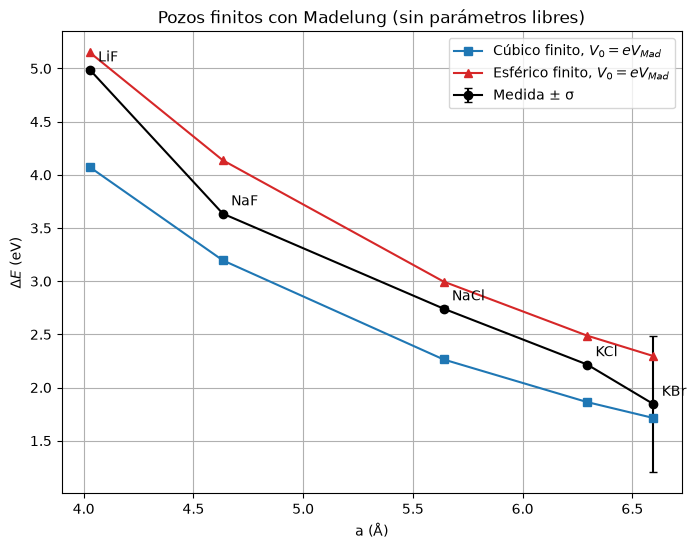

In [99]:
filas = {}
for h in tabla.index:
    a_h, R0_h, V = tabla.loc[h, "a (Å)"], tabla.loc[h, "R0 = a/2 (Å)"], tabla.loc[h, "eV_Mad (eV)"]
    filas[h] = {
        "ΔE cúbico finito (eV)": delta_E_separable(V, a_h),     # arista a
        "ΔE esférico finito (eV)": delta_E(V, R0_h),            # radio a/2
        "E_F medida (eV)": tabla.loc[h, "E_F (eV)"],
    }
comp = pd.DataFrame.from_dict(filas, orient="index")
comp["dif. cúbico (%)"] = 100 * (comp["ΔE cúbico finito (eV)"] / comp["E_F medida (eV)"] - 1)
comp["dif. esférico (%)"] = 100 * (comp["ΔE esférico finito (eV)"] / comp["E_F medida (eV)"] - 1)

# V0 que hace coincidir el cubo con E_F (brentq sobre ΔE(V0) - E_F) y su β = V0 / eV_Mad
def ajustar_V0_cubo(E_medida, a, V_ini):
    return brentq(lambda V: delta_E_separable(V, a) - E_medida, 0.3 * V_ini, 5 * V_ini, xtol=1e-3)

comp["β cúbico"] = [ajustar_V0_cubo(tabla.loc[h, "E_F (eV)"], tabla.loc[h, "a (Å)"], tabla.loc[h, "eV_Mad (eV)"])
                    / tabla.loc[h, "eV_Mad (eV)"] for h in tabla.index]
comp["β esférico"] = madelung["β = V0 ajustado / eV_Mad"]
print(comp.round(3).to_string())

fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(tabla["a (Å)"], tabla["E_F (eV)"], yerr=tabla["err E_F (eV)"], fmt="ko-", capsize=3, label="Medida ± σ")
ax.plot(tabla["a (Å)"], comp["ΔE cúbico finito (eV)"], "s-", color="tab:blue", label=r"Cúbico finito, $V_0=eV_{Mad}$")
ax.plot(tabla["a (Å)"], comp["ΔE esférico finito (eV)"], "^-", color="tab:red", label=r"Esférico finito, $V_0=eV_{Mad}$")
for h in tabla.index:
    ax.annotate(h, (tabla.loc[h, "a (Å)"], tabla.loc[h, "E_F (eV)"]), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("a (Å)"); ax.set_ylabel(r"$\Delta E$ (eV)")
ax.set_title("Pozos finitos con Madelung (sin parámetros libres)")
ax.legend(); ax.grid(True)
plt.show()

# 7. Distancia efectiva $a_{eff} = \alpha\,a$ (pozo esférico finito)

$$R_{eff}=\alpha\,\frac a2,\qquad V_0=\frac{e^2}{4\pi\varepsilon_0}\frac{M}{R_{eff}},\qquad r_0=R_{eff}$$

In [100]:
# Un solo parámetro geométrico α que cambia A LA VEZ la profundidad (Madelung con R_eff) y el radio del pozo
haluros = list(tabla.index)
E_F, sE_F, R0 = tabla["E_F (eV)"], tabla["err E_F (eV)"], tabla["R0 = a/2 (Å)"]

# Pesos 1/σ² con σ = incerteza relativa de E_F (+ piso de 1 %): KBr casi no pesa
pesos = 1 / np.hypot(sE_F / E_F, SIGMA_PISO) ** 2

def dE_esfera(alfa, h):
    # ΔE del pozo esférico finito con R_eff = α·a/2 en profundidad y radio
    R = alfa * R0[h]
    return delta_E(e2_4pieps0 * M_madelung / R, R)

def error_rel(alfa):
    # (ΔE/E_F - 1) en % para cada haluro
    return pd.Series({h: 100 * (dE_esfera(alfa, h) / E_F[h] - 1) for h in haluros})

def rms(err):
    # rms ponderado (%): es lo que minimiza el α global
    return float(np.sqrt(np.sum(pesos[err.index] * err**2) / np.sum(pesos[err.index])))

def alfa_exacto(h, E_objetivo):
    # α_i que reproduce exactamente E_objetivo en el haluro h (ΔE baja al crecer α). NaN si no hay raíz en [0.8, 1.6]
    try:
        return brentq(lambda al: dE_esfera(al, h) - E_objetivo, 0.8, 1.6, xtol=1e-3)
    except ValueError:
        return np.nan

# (i) α global: un único valor para todos los haluros, el que minimiza el rms ponderado
alfa_global = minimize_scalar(lambda al: rms(error_rel(al)), bounds=(0.9, 1.4), method="bounded", options={"xatol": 1e-3}).x

# (ii) α_i por haluro, con la incerteza propagada repitiendo con E_F ± σ (E mayor -> α menor)
alfas = pd.DataFrame({h: {"alpha_i": alfa_exacto(h, E_F[h]),
                          "alpha_i (E+σ)": alfa_exacto(h, E_F[h] + sE_F[h]),
                          "alpha_i (E−σ)": alfa_exacto(h, E_F[h] - sE_F[h])} for h in haluros}).T

err_global, err_uno = error_rel(alfa_global), error_rel(1.0)
print(f"α global = {alfa_global:.3f}  ->  a_eff/a;  rms ponderado: {rms(err_global):.2f} %  (con α = 1: {rms(err_uno):.2f} %)")
print("\nError relativo de ΔE respecto de E_F (%):")
print(pd.DataFrame({"α = 1": err_uno, f"α = {alfa_global:.3f}": err_global}).round(2).T.to_string())
print("\nα_i que reproduce exactamente E_F de cada haluro:")
print(alfas.round(3).to_string())

α global = 1.060  ->  a_eff/a;  rms ponderado: 3.59 %  (con α = 1: 10.67 %)

Error relativo de ΔE respecto de E_F (%):
            LiF    NaF  NaCl    KCl    KBr
α = 1      3.24  13.81  9.29  12.25  24.47
α = 1.060 -5.65   3.55 -0.98   1.53  12.51

α_i que reproduce exactamente E_F de cada haluro:
      alpha_i  alpha_i (E+σ)  alpha_i (E−σ)
LiF     1.021          1.019          1.023
NaF     1.083          1.083          1.084
NaCl    1.054          1.049          1.059
KCl     1.070          1.069          1.070
KBr     1.134          0.954          1.445


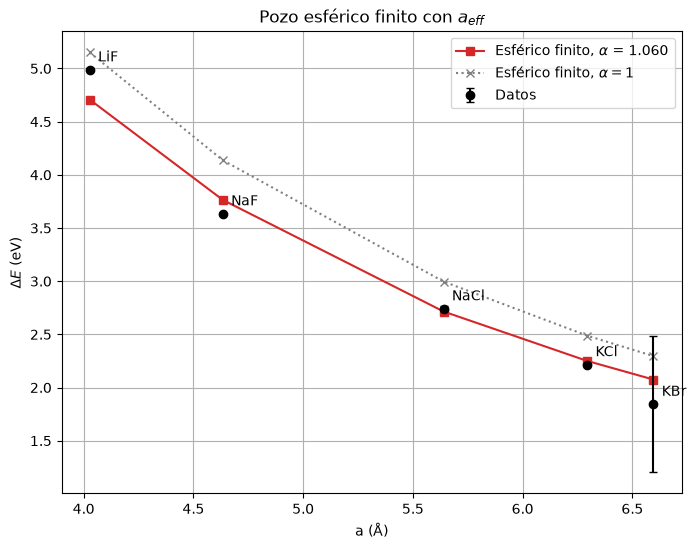

In [101]:
# E_F medida vs esférico finito con α global y con α = 1
a_h = tabla["a (Å)"]
fig, ax = plt.subplots(figsize=(8, 6))
ax.errorbar(a_h, E_F, yerr=sE_F, fmt="ko", capsize=3, label="Datos", zorder=5)
ax.plot(a_h, [dE_esfera(alfa_global, h) for h in haluros], "s-", color="tab:red", label=rf"Esférico finito, $\alpha$ = {alfa_global:.3f}")
ax.plot(a_h, [dE_esfera(1.0, h) for h in haluros], "x:", color="gray", label=r"Esférico finito, $\alpha=1$")
for h in haluros:
    ax.annotate(h, (a_h[h], E_F[h]), textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("a (Å)"); ax.set_ylabel(r"$\Delta E$ (eV)")
ax.set_title(r"Pozo esférico finito con $a_{eff}$")
ax.legend(); ax.grid(True)
plt.show()

# 8. Resumen

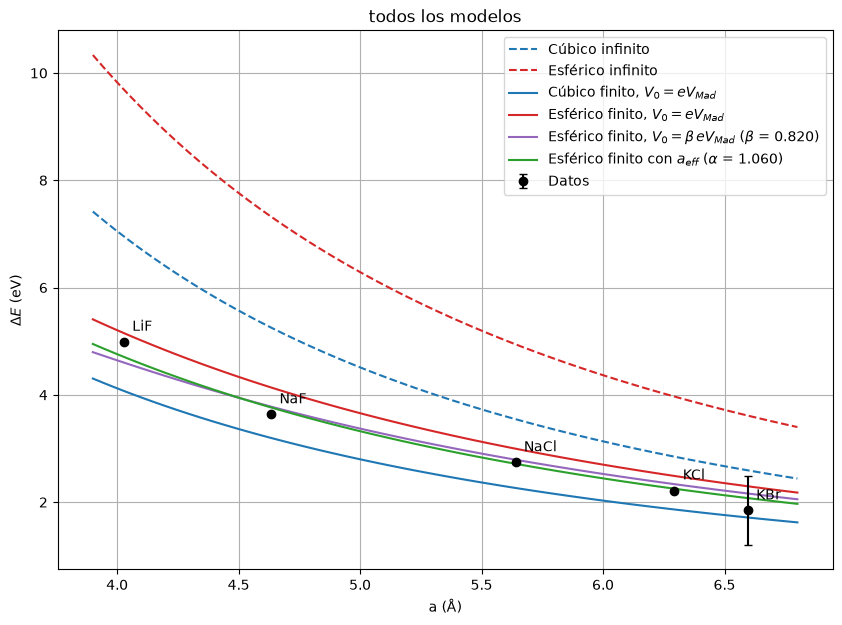

In [102]:
# Cada modelo se evalúa en una grilla de constantes de red (V0 = eV_Mad(R) con R = a/2, salvo el último)
a_plot = np.linspace(3.9, 6.8, 60)
c_mad = e2_4pieps0 * M_madelung            # e²/(4πε0)·M  -> eV_Mad = c_mad / R

curvas = {
    "Cúbico infinito":                      (3 * np.pi**2 * hb2_2m / a_plot**2, "tab:blue", "--"),
    "Esférico infinito":                    (10.315 * hb2_2m / (a_plot / 2) ** 2, "tab:red", "--"),
    r"Cúbico finito, $V_0=eV_{Mad}$":       (np.array([delta_E_separable(c_mad / (a / 2), a) for a in a_plot]), "tab:blue", "-"),
    r"Esférico finito, $V_0=eV_{Mad}$":     (np.array([delta_E(c_mad / (a / 2), a / 2) for a in a_plot]), "tab:red", "-"),
    rf"Esférico finito, $V_0=\beta\,eV_{{Mad}}$ ($\beta$ = {beta_libre:.3f})":
                                            (np.array([delta_E(beta_libre * c_mad / (a / 2), a / 2) for a in a_plot]), "tab:purple", "-"),
    rf"Esférico finito con $a_{{eff}}$ ($\alpha$ = {alfa_global:.3f})":
                                            (np.array([delta_E(c_mad / (alfa_global * a / 2), alfa_global * a / 2) for a in a_plot]), "tab:green", "-"),
}

fig, ax = plt.subplots(figsize=(10, 7))
for nombre, (E, color, estilo) in curvas.items():
    ax.plot(a_plot, E, estilo, color=color, label=nombre)
ax.errorbar(tabla["a (Å)"], tabla["E_F (eV)"], yerr=tabla["err E_F (eV)"], fmt="ko", capsize=3, label="Datos", zorder=5)
for h in tabla.index:
    ax.annotate(h, (tabla.loc[h, "a (Å)"], tabla.loc[h, "E_F (eV)"]), textcoords="offset points", xytext=(6, 8))
ax.set_xlabel("a (Å)"); ax.set_ylabel(r"$\Delta E$ (eV)")
ax.set_title("todos los modelos")
ax.legend(); ax.grid(True)
plt.show()

                                        rms ponderado (%)
Esférico finito con $a_{eff}$                         3.6
Esférico finito, $V_0=\beta\,eV_{Mad}$                5.4
Esférico finito, $V_0=eV_{Mad}$                      10.7
Cúbico finito, $V_0=eV_{Mad}$                        15.9
Cúbico infinito                                      36.7
Esférico infinito                                    90.1


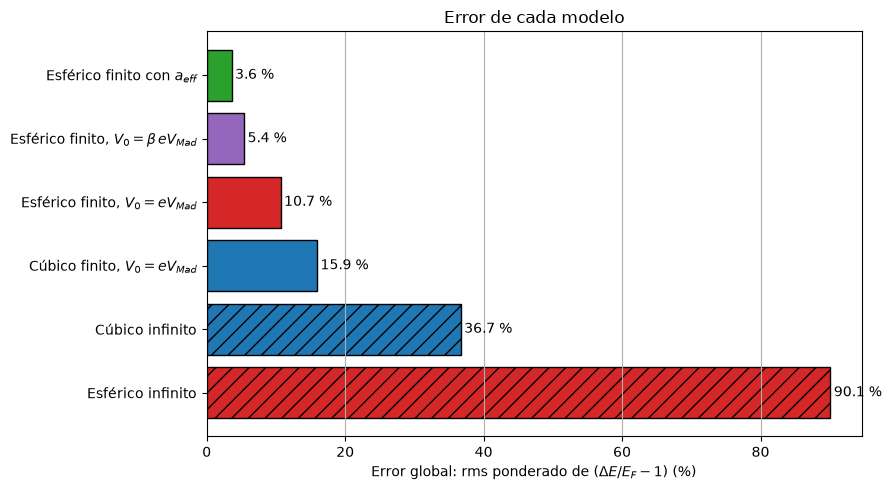

In [103]:
# Error global de cada modelo: rms ponderado (%) de (ΔE/E_F - 1) sobre los 5 haluros,
# con los mismos pesos que en la sección 7 (KBr casi no pesa por su incerteza grande).
dE_modelos = {
    "Cúbico infinito":                         tabla["E cúbico inf (eV)"],
    "Esférico infinito":                       tabla["E esférico inf (eV)"],
    r"Cúbico finito, $V_0=eV_{Mad}$":          comp["ΔE cúbico finito (eV)"],
    r"Esférico finito, $V_0=eV_{Mad}$":        madelung["ΔE Madelung (eV)"],
    r"Esférico finito, $V_0=\beta\,eV_{Mad}$": pd.Series(dE_beta, index=haluros),
    r"Esférico finito con $a_{eff}$":          pd.Series({h: dE_esfera(alfa_global, h) for h in haluros}),
}
colores_modelos = dict(zip(dE_modelos, ["tab:blue", "tab:red", "tab:blue", "tab:red", "tab:purple", "tab:green"]))
rayados = dict(zip(dE_modelos, ["//", "//", "", "", "", ""]))     # rayado = pozo infinito

filas_err = {}
for nombre, dE in dE_modelos.items():
    err = 100 * (dE.astype(float) / E_F - 1)
    filas_err[nombre] = {"rms ponderado (%)": rms(err)}
ranking = pd.DataFrame(filas_err).T.sort_values("rms ponderado (%)")      # de menor a mayor error
print(ranking.round(1).to_string())

fig, ax = plt.subplots(figsize=(9, 5))
for i, (nombre, v) in enumerate(ranking["rms ponderado (%)"].items()):
    ax.barh(i, v, color=colores_modelos[nombre], hatch=rayados[nombre], edgecolor="k")
    ax.text(v + 0.5, i, f"{v:.1f} %", va="center")
ax.set_yticks(range(len(ranking))); ax.set_yticklabels(ranking.index)
ax.invert_yaxis()                                      # el menor error arriba
ax.set_xlabel(r"Error global: rms ponderado de $(\Delta E/E_F - 1)$ (%)")
ax.set_title("Error de cada modelo")
ax.grid(True, axis="x")
plt.tight_layout()
plt.show()